# AI-Driven Credit Card Fraud Detection
**Arch Store | Offline SOC detection engineering lab**

An e-commerce SOC needs to prioritize suspected card fraud while keeping legitimate
transactions out of the alert queue. This six-cell notebook uses the original
ULB/Worldline credit-card benchmark, Random Forest and training-only SMOTE.

The 99.8% figure describes the approximate legitimate share of the raw dataset.
The measurable operating target here is **at least 99.8% legitimate suppression
(specificity)** at a **fixed 0.50 score threshold**, with fraud precision, recall
and false negatives reported separately. The threshold is set before evaluation.

Exact duplicate transactions are removed before the stratified 80/20 split.
The scaler is fit on training data only. The holdout retains natural class imbalance.
This is supervised fraud classification; this dataset cannot establish bot identity.

Run from the project root. First install `requirements.txt` and run
`python scripts/download_data.py`. Execute all cells in order, or use
`python scripts/run_notebook.py`. Outputs, figures, metrics and HIGH review alerts
are saved locally; the dataset and trained model are ignored by Git.

## Cell 1 — Import libraries and define the alert policy

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata as metadata
import json
import platform
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, roc_auc_score)
from imblearn.over_sampling import SMOTE
from fraud_engine import (FEATURE_COLUMNS, THRESHOLD, MODEL_VERSION,
                          transform_transactions, score_transactions, validate_features)

get_ipython().run_line_magic("matplotlib", "inline")
ROOT = Path.cwd()
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
for folder in [REPORTS, FIGURES, ROOT / "models", ROOT / "screenshots"]:
    folder.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 180})
SEED = 42
versions = {p: metadata.version(p) for p in
            ["pandas", "numpy", "scipy", "scikit-learn", "imbalanced-learn",
             "matplotlib", "seaborn", "joblib"]}
print("Libraries imported successfully | Python", platform.python_version())
print(json.dumps(versions, indent=2))
print(f"Alert policy: HIGH analyst-review alert when score >= {THRESHOLD:.2f}")
print("Operating target: legitimate suppression >= 99.8%; random seed = 42")

Libraries imported successfully | Python 3.13.13
{
  "pandas": "2.3.3",
  "numpy": "2.2.6",
  "scipy": "1.16.3",
  "scikit-learn": "1.7.2",
  "imbalanced-learn": "0.14.0",
  "matplotlib": "3.10.7",
  "seaborn": "0.13.2",
  "joblib": "1.5.2"
}
Alert policy: HIGH analyst-review alert when score >= 0.50
Operating target: legitimate suppression >= 99.8%; random seed = 42


## Cell 2 — Load and analyze baseline traffic
The baseline chart uses all original records. Dataset provenance is recorded
separately. Fraud labels are used for training and evaluation, never as input features.

Total Transactions:      284,807
Fraudulent Transactions: 492 (0.1727%)
Legitimate Transactions: 284,315 (99.8273%)
Missing values: 0 | Exact duplicate rows: 1,081


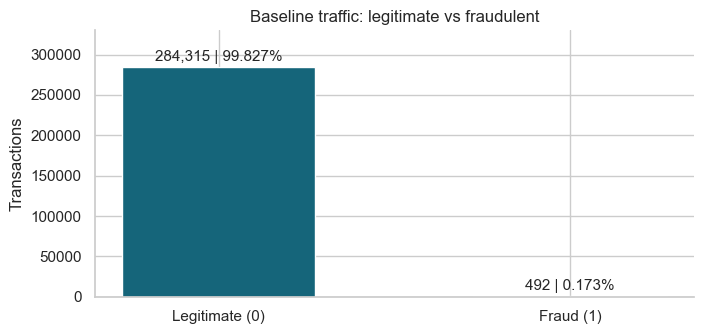

In [2]:
data_path = ROOT / "data" / "creditcard.csv"
df = pd.read_csv(data_path)
assert list(df.columns) == FEATURE_COLUMNS + ["Class"], "Unexpected dataset schema"
validate_features(df.drop(columns="Class"))
assert set(df["Class"].unique()) == {0, 1}
raw_counts = df["Class"].value_counts().sort_index()
assert (len(df), int(raw_counts[0]), int(raw_counts[1])) == (284807, 284315, 492)
dataset_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
duplicate_count = int(df.duplicated().sum())
print(f"Total Transactions:      {len(df):,}")
print(f"Fraudulent Transactions: {raw_counts[1]:,} ({raw_counts[1]/len(df):.4%})")
print(f"Legitimate Transactions: {raw_counts[0]:,} ({raw_counts[0]/len(df):.4%})")
print(f"Missing values: {df.isna().sum().sum()} | Exact duplicate rows: {duplicate_count:,}")

fig, ax = plt.subplots(figsize=(7.2, 3.5))
bars = ax.bar(["Legitimate (0)", "Fraud (1)"], raw_counts.to_numpy(),
              color=["#15657a", "#d45143"], width=0.55)
for bar, count in zip(bars, raw_counts):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+8000,
            f"{count:,} | {count/len(df):.3%}", ha="center", fontsize=11)
ax.set(title="Baseline traffic: legitimate vs fraudulent", ylabel="Transactions", ylim=(0, 330000))
ax.ticklabel_format(style="plain", axis="y")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(FIGURES / "baseline-traffic.png", bbox_inches="tight")
plt.show()

## Cell 3 — Prevent leakage and preprocess
Remove identical transactions before splitting. Preserve original row IDs for
auditability. Fit StandardScaler on training Amount and Time only; reuse it for
holdout and future scoring. The PCA components remain in their supplied form.

In [3]:
clean_df = df.drop_duplicates().copy()
X = clean_df.drop(columns="Class")
y = clean_df["Class"].astype(int)
assert not X.duplicated().any(), "Conflicting labels or duplicate feature rows require review"
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
scaler = StandardScaler()
scaler.fit(X_train_raw[["Amount", "Time"]])
X_train = transform_transactions(X_train_raw, scaler)
X_test = transform_transactions(X_test_raw, scaler)
train_hashes = set(pd.util.hash_pandas_object(X_train_raw, index=False))
test_hashes = set(pd.util.hash_pandas_object(X_test_raw, index=False))
overlap = len(train_hashes & test_hashes)
assert overlap == 0 and set(X_train.index).isdisjoint(X_test.index)
assert scaler.n_samples_seen_ == len(X_train)
print(f"Exact duplicates removed: {len(df)-len(clean_df):,}")
print(f"Unique transactions: {len(clean_df):,} | Fraud labels: {y.sum():,}")
print(f"Training set: {len(y_train):,} | Legitimate: {(y_train==0).sum():,} | Fraud: {y_train.sum():,}")
print(f"Test set:     {len(y_test):,} | Legitimate: {(y_test==0).sum():,} | Fraud: {y_test.sum():,}")
print(f"Training / test feature overlap: {overlap}")
print(f"Scaler fitted on {scaler.n_samples_seen_:,} training rows only; features: {X_train.shape[1]}")
print("PASS: labels excluded, holdout untouched, finite features, no duplicate overlap.")

Exact duplicates removed: 1,081
Unique transactions: 283,726 | Fraud labels: 473
Training set: 226,980 | Legitimate: 226,602 | Fraud: 378
Test set:     56,746 | Legitimate: 56,651 | Fraud: 95
Training / test feature overlap: 0
Scaler fitted on 226,980 training rows only; features: 30
PASS: labels excluded, holdout untouched, finite features, no duplicate overlap.


## Cell 4 — Handle the SOC imbalance with training-only SMOTE
SMOTE produces synthetic minority-class feature vectors for training. These
examples are not real transactions or evidence of additional fraud incidents.

Original Training Data: 226,980
Balanced Training Data (after SMOTE): 453,204
Before: legitimate=226,602, fraud=378
After:  legitimate=226,602, fraud=226,602
Synthetic fraud training samples: 226,224
Test set remains unchanged: 56,746 real transactions


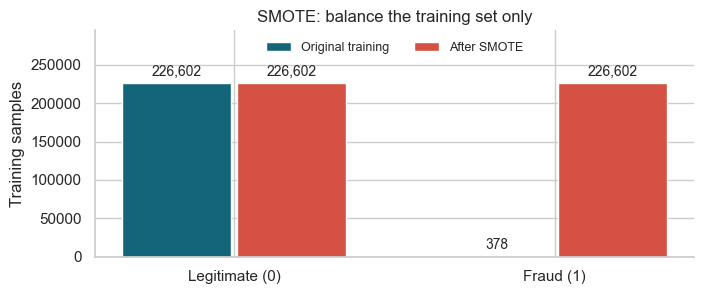

In [4]:
smote = SMOTE(random_state=SEED)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
before = y_train.value_counts().reindex([0, 1])
after = y_train_resampled.value_counts().reindex([0, 1])
assert after[0] == after[1]
print(f"Original Training Data: {len(y_train):,}")
print(f"Balanced Training Data (after SMOTE): {len(y_train_resampled):,}")
print(f"Before: legitimate={before[0]:,}, fraud={before[1]:,}")
print(f"After:  legitimate={after[0]:,}, fraud={after[1]:,}")
print(f"Synthetic fraud training samples: {after[1]-before[1]:,}")
print(f"Test set remains unchanged: {len(y_test):,} real transactions")

fig, ax = plt.subplots(figsize=(7.2, 3.1))
x = np.arange(2)
for offset, counts, label, color in [(-0.18, before, "Original training", "#15657a"),
                                    (0.18, after, "After SMOTE", "#d45143")]:
    bars = ax.bar(x+offset, counts, width=0.34, label=label, color=color)
    ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=3, fontsize=10)
ax.set(xticks=x, xticklabels=["Legitimate (0)", "Fraud (1)"],
       ylabel="Training samples", title="SMOTE: balance the training set only")
ax.set_ylim(0, after.max()*1.30)
ax.legend(loc="upper center", ncol=2, frameon=False, fontsize=9)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(FIGURES / "smote-balancing.png", bbox_inches="tight")
plt.show()

## Cell 5 — Train and save the detection engine
Random Forest is a supervised classifier trained on historical fraud labels.
The model bundle preserves preprocessing, the fixed policy and package versions.

In [5]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
training_started = time.perf_counter()
rf_model.fit(X_train_resampled, y_train_resampled)
training_seconds = time.perf_counter() - training_started
bundle = {"model": rf_model, "scaler": scaler, "threshold": THRESHOLD,
          "model_version": MODEL_VERSION, "feature_columns": FEATURE_COLUMNS,
          "versions": versions, "random_state": SEED,
          "dataset_sha256": dataset_sha256}
model_path = ROOT / "models" / "fraud_engine.joblib"
joblib.dump(bundle, model_path, compress=3)
print("Detection Engine Trained Successfully!")
print(f"Algorithm: supervised Random Forest | Trees: {len(rf_model.estimators_)}")
print(f"Training samples: {len(y_train_resampled):,} | Features: {X_train.shape[1]}")
print(f"Training duration: {training_seconds:.2f} seconds")
print(f"Model bundle saved: models/fraud_engine.joblib ({model_path.stat().st_size/1024**2:.2f} MiB)")
print(f"HIGH alert threshold: {THRESHOLD:.2f}; test data has not been used to fit the model.")

Detection Engine Trained Successfully!
Algorithm: supervised Random Forest | Trees: 100
Training samples: 453,204 | Features: 30
Training duration: 253.63 seconds
Model bundle saved: models/fraud_engine.joblib (4.18 MiB)
HIGH alert threshold: 0.50; test data has not been used to fit the model.


## Cell 6 — Evaluate and generate SOC review alerts
Evaluate the untouched holdout at the fixed threshold. A high score queues an
analyst-review alert; it does not prove fraud or block a customer's payment.
Scores from a model trained on SMOTE data are not calibrated probabilities.

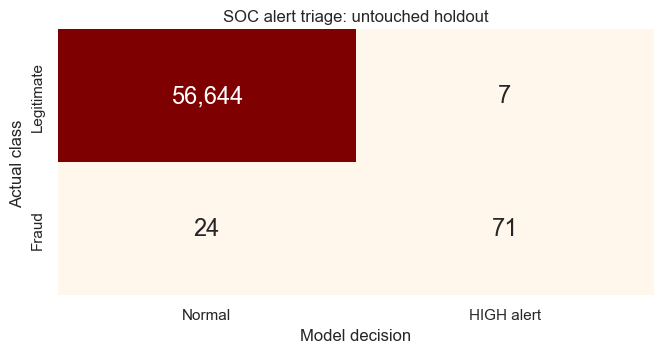

--- SOC Detection Report | fixed threshold = 0.50 ---
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9999    0.9997     56651
       Fraud     0.9103    0.7474    0.8208        95

    accuracy                         0.9995     56746
   macro avg     0.9549    0.8736    0.9103     56746
weighted avg     0.9994    0.9995    0.9994     56746

Legitimate suppression (specificity): 99.9876%
False-positive rate: 0.0124% | Missed fraud: 24
HIGH review alerts: 78 / 56,746
Average precision: 0.8072
99.8% legitimate-suppression target met: True


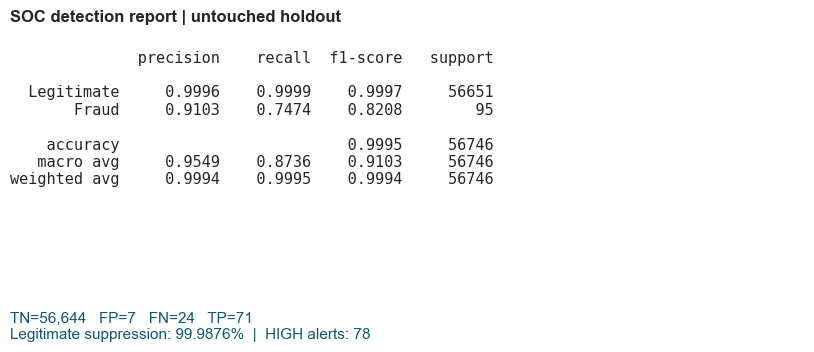

Sample HIGH analyst-review alert (benchmark replay):
{
  "event_type": "transaction_fraud_suspected",
  "detection_id": "ARCH-ML-001",
  "model_version": "arch-rf-smote-v1",
  "transaction_id": "ulb-row-116139",
  "severity": "HIGH",
  "score": 0.98,
  "threshold": 0.5,
  "action": "analyst_review",
  "generated_at_utc": "2026-11-18T17:14:27.842102+00:00",
  "reason": "Random Forest fraud score meets the fixed alert threshold"
}
Saved metrics, per-row predictions and HIGH alerts under reports/.


In [6]:
scores = rf_model.predict_proba(X_test)[:, 1]
y_pred = (scores >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = map(int, cm.ravel())
report = classification_report(y_test, y_pred, labels=[0, 1],
                               target_names=["Legitimate", "Fraud"], digits=4, zero_division=0)
report_dict = classification_report(y_test, y_pred, labels=[0, 1], output_dict=True, zero_division=0)
evaluation = {"test_transactions": len(y_test), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
              "fraud_precision": report_dict["1"]["precision"],
              "fraud_recall": report_dict["1"]["recall"],
              "fraud_f1": report_dict["1"]["f1-score"],
              "specificity": tn/(tn+fp), "false_positive_rate": fp/(tn+fp),
              "alert_count": tp+fp, "alert_rate": (tp+fp)/len(y_test),
              "suppressed_traffic_fraction": (tn+fn)/len(y_test),
              "average_precision": float(average_precision_score(y_test, scores)),
              "roc_auc": float(roc_auc_score(y_test, scores)),
              "accuracy": report_dict["accuracy"],
              "all_normal_baseline_accuracy": float((y_test==0).mean()),
              "specificity_target": 0.998, "specificity_target_met": bool(tn/(tn+fp) >= 0.998)}
metrics = {"generated_at_utc": datetime.now(timezone.utc).isoformat(), "threshold": THRESHOLD,
           "model_version": MODEL_VERSION, "random_state": SEED, "dataset_sha256": dataset_sha256,
           "dataset": {"raw_rows": len(df), "raw_legitimate": int(raw_counts[0]),
                       "raw_fraud": int(raw_counts[1]), "duplicates_removed": duplicate_count,
                       "unique_rows": len(clean_df), "unique_fraud": int(y.sum())},
           "training": {"rows": len(y_train), "legitimate": int(before[0]), "fraud": int(before[1]),
                        "resampled_rows": len(y_train_resampled), "resampled_per_class": int(after[0]),
                        "training_seconds": training_seconds, "duplicate_overlap": overlap},
           "evaluation": evaluation, "classification_report": report_dict, "versions": versions}
(REPORTS / "metrics.json").write_text(json.dumps(metrics, indent=2)+"\n", encoding="utf-8")
(REPORTS / "classification_report.txt").write_text(report, encoding="utf-8")
predictions = pd.DataFrame({"source_row": X_test_raw.index, "actual_class": y_test.to_numpy(),
                            "fraud_score": scores, "predicted_class": y_pred})
predictions.to_csv(REPORTS / "test_predictions.csv", index=False)
alerts = score_transactions(X_test_raw, bundle,
                            transaction_ids=[f"ulb-row-{i}" for i in X_test_raw.index])
assert len(alerts) == tp + fp
(REPORTS / "high_severity_alerts.jsonl").write_text(
    "".join(json.dumps(alert)+"\n" for alert in alerts), encoding="utf-8")

fig, ax = plt.subplots(figsize=(6.8, 3.7))
sns.heatmap(cm, annot=True, fmt=",d", cmap="OrRd", cbar=False, ax=ax,
            xticklabels=["Normal", "HIGH alert"], yticklabels=["Legitimate", "Fraud"],
            annot_kws={"fontsize": 17})
ax.set(title="SOC alert triage: untouched holdout", xlabel="Model decision", ylabel="Actual class")
fig.tight_layout()
fig.savefig(FIGURES / "confusion-matrix.png", bbox_inches="tight")
plt.show()
print("--- SOC Detection Report | fixed threshold = 0.50 ---")
print(report)
print(f"Legitimate suppression (specificity): {evaluation['specificity']:.4%}")
print(f"False-positive rate: {evaluation['false_positive_rate']:.4%} | Missed fraud: {fn}")
print(f"HIGH review alerts: {len(alerts):,} / {len(y_test):,}")
print(f"Average precision: {evaluation['average_precision']:.4f}")
print(f"99.8% legitimate-suppression target met: {evaluation['specificity_target_met']}")
fig, ax = plt.subplots(figsize=(8.3, 3.7))
ax.axis("off")
ax.set_title("SOC detection report | untouched holdout", loc="left", fontweight="bold", pad=14)
ax.text(0, 0.97, report, family="monospace", fontsize=11, va="top", transform=ax.transAxes)
summary = (f"TN={tn:,}   FP={fp:,}   FN={fn:,}   TP={tp:,}\n"
           f"Legitimate suppression: {evaluation['specificity']:.4%}  |  HIGH alerts: {len(alerts):,}")
ax.text(0, 0.10, summary, fontsize=11, va="top", transform=ax.transAxes, color="#12576b")
fig.tight_layout()
fig.savefig(FIGURES / "detection-report.png", bbox_inches="tight")
plt.show()
print("Sample HIGH analyst-review alert (benchmark replay):")
print(json.dumps(alerts[0], indent=2) if alerts else "No alerts at this threshold.")
print("Saved metrics, per-row predictions and HIGH alerts under reports/.")

## Interpretation and next steps
Precision measures how many review alerts are real fraud in this holdout; recall
measures how many known fraud cases were detected. Specificity measures the
legitimate transactions kept out of the queue. Accuracy alone is misleading
because an all-normal classifier is already approximately 99.8% accurate.

This historical, anonymized benchmark contains no IP, device, session, payment
response or account-login context. It does not demonstrate a live Arch Store
bot attack or a production improvement over a firewall. Validate chronologically
on recent merchant data, calibrate scores on a separate validation set, choose
thresholds against review capacity and loss, and monitor drift before deployment.

Sources: [Kaggle dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud),
[official TensorFlow mirror reference](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data),
[imbalanced-learn leakage guidance](https://imbalanced-learn.org/stable/common_pitfalls.html).